# Organic history

This notebook runs an organic culture history on a generated planet: peoples start as foragers, take up farming, raise their energy, transport and communication, form states, fight, colonise, mix and meet the planet's eruptions, droughts and pandemics. It then reads the chronicle, plots the history over time, draws maps at the kept epochs and zooms into a region as it stood in the past.

Run it from the `notebooks/` folder after `pip install -e ".[dev,notebooks]"`. The notebook takes a few minutes.

In [1]:
%matplotlib inline
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image

from worldgen import generate_world, load_spec, load_world, save_world
from worldgen.culture import CultureSpec, apply_culture, format_chronicle, world_at_epoch
from worldgen.render import animate_epochs, plot_chronicle, plot_epochs, plot_local_map, plot_map
from worldgen.report import format_culture

## 1. A planet

The Earth example on the standard grid (40k cells) with the full plate simulation. The preview grid is not used here: its flatter relief floods more land than the standard grid (10–19% against 24–27% for the same spec).

In [2]:
world = generate_world(load_spec("../examples/earth.yaml"), resolution="standard")
print(world.state.name, f"land {1 - world.surface['ocean'].values.mean():.0%}")

Earth land 27%


## 2. An organic culture spec

`mode: organic` makes a culture's development, people and states emerge from the history instead of being given. The `history` block sets the span (default 12 000 years), the epochs to keep, and events placed by hand. The planet's own eruptions, droughts, pandemics and impacts are drawn at their rates unless `planet_events` is false. An organic colony lands at its date with its given development.

In [3]:
s = world.surface
land, lat, lon = ~s["ocean"].values, s.lat.values, s.lon.values
south = np.flatnonzero(land & (lat < -10))                     # a homeland for Bel in the south
temperate = np.flatnonzero(land & (np.abs(lat - 40) < 8))      # a landing site for Corin
bel, site = south[south.size // 2], temperate[temperate.size // 3]
place = lambda cell: {"lat_deg": float(lat[cell]), "lon_deg": float(lon[cell])}

culture = CultureSpec.model_validate({
    "history": {
        "start_years_ago": 8000,
        "epochs": [6000, 4000, 2000, 1000, 500],
        "events": [
            {"kind": "drought", "years_ago": 4200, **place(site), "size": 0.4, "radius_km": 1500,
             "duration_years": 250},
            {"kind": "eruption", "years_ago": 1500, "size": 50},
        ],
    },
    "cultures": [
        {"name": "Aru", "mode": "organic"},
        {"name": "Bel", "mode": "organic", "homeland": {**place(bel), "radius_km": 3000}},
        {"name": "Corin", "mode": "organic", "inhabitants": "colonist",
         "development": {"energy": "water_wind", "transport": "wheel_and_sail", "communication": "print"},
         "colony": {"founded_years_ago": 700, "landing_sites": [place(site)]}},
    ],
})
world = apply_culture(world, culture)
civ = world.culture
print(format_culture(civ, world))


Culture
  cultures                    8
  settlements listed          9609
  polities                    43
  epoch                       present
  earlier epochs kept         6,000, 4,000, 2,000, 1,000, 500 years ago

  Aru (native, organic)
  development                 farming, wheel_and_sail, writing
  population                  40.2 M
  largest settlements         Ngaqa (90.2 k), Chunlu (86.4 k), Hoyimlom (85 k), Pebotis (78.8 k), Ilulralom (74 k)
  settlement forms            village 6669, town 1037
  polities                    3; largest Tisa'ukwi (empire, 2.19 M km²), Nèemlipmèw (empire, 2.01 M km²), Siyrinakwi (kingdom, 0.06 M km²)
  roads (grid, km)            track 791,926, road 395,940, trunk 197,965, sea route 100,219
  sound system                30 consonants, 7 vowels, moderate syllables

  Bel (native, organic)
  development                 farming, pack_and_boat, oral
  population                  1.69 M
  largest settlements         Qhlùnyukwikim (11.6 k), Iitku (

The report ends with the history table: each kept epoch's people, cultures, states, largest state and the highest levels reached. Cultures that arose during the history (overseas colonies of the natives' states, creoles) appear with their own names.

## 3. The chronicle

`format_chronicle` writes major entries in full and counts minor ones (secessions, conquests, small wars) per period. It filters by time, kind and culture; state and culture numbers are replaced by names where a kept epoch named them. `worldgen chronicle <world>` prints the same from the command line.

In [4]:
print(format_chronicle(civ, since=2000, until=500))

2,000 years ago to 1,500 years ago
     1,853  An eruption at -23.2°, 27.8° puts 31 Tg of sulfur into the stratosphere; summers in the southern hemisphere cool by 1.1 K for 10 years
     1,764  A drought takes 35% of the rain within 654 km of -16.7°, -86.4° for 186 years
     1,601  A drought takes 30% of the rain within 1,166 km of 26.3°, 85.2° for 212 years
     1,561  An eruption at -25.7°, 23.9° puts 33 Tg of sulfur into the stratosphere; summers in the southern hemisphere cool by 1.2 K for 10 years

1,500 years ago to 1,000 years ago
     1,500  An eruption at -67.9°, -99.6° puts 50 Tg of sulfur into the stratosphere; summers in the southern hemisphere cool by 1.5 K for 10 years
     1,474  An eruption at 4.0°, -1.9° puts 32 Tg of sulfur into the stratosphere; summers in both hemispheres cool by 1.2 K for 10 years
     1,450  The first state arises at 44.7°, 89.8°
     1,421  An eruption at 2.3°, -2.1° puts 40 Tg of sulfur into the stratosphere; summers in both hemispheres cool by

In [5]:
print(format_chronicle(civ, kinds=["independence", "creole", "pandemic", "eruption", "drought"], minor="hide"))

8,000 years ago to 7,000 years ago
     7,771  A drought takes 47% of the rain within 911 km of 3.3°, 70.0° for 207 years
     7,558  A drought takes 23% of the rain within 660 km of 26.9°, 36.3° for 297 years
     7,214  A drought takes 22% of the rain within 672 km of 22.8°, -6.2° for 105 years
     7,094  A drought takes 26% of the rain within 1,771 km of 58.2°, 32.0° for 182 years

7,000 years ago to 6,000 years ago
     6,993  An eruption at -70.5°, -102.1° puts 60 Tg of sulfur into the stratosphere; summers in the southern hemisphere cool by 1.6 K for 10 years
     6,952  A drought takes 30% of the rain within 769 km of 51.4°, 0.2° for 189 years
     6,784  An eruption at 3.3°, -2.5° puts 41 Tg of sulfur into the stratosphere; summers in both hemispheres cool by 1.3 K for 10 years
     6,780  A drought takes 49% of the rain within 1,927 km of -41.4°, -28.2° for 137 years
     6,592  A drought takes 27% of the rain within 573 km of 1.4°, 105.2° for 176 years
     6,475  A drought 

## 4. The history over time

The history records each culture's people, land, states and mean levels at every step (`civ.series`). `plot_chronicle` draws people and mean energy per culture with the chronicle's major entries below; dotted lines mark the kept epochs.

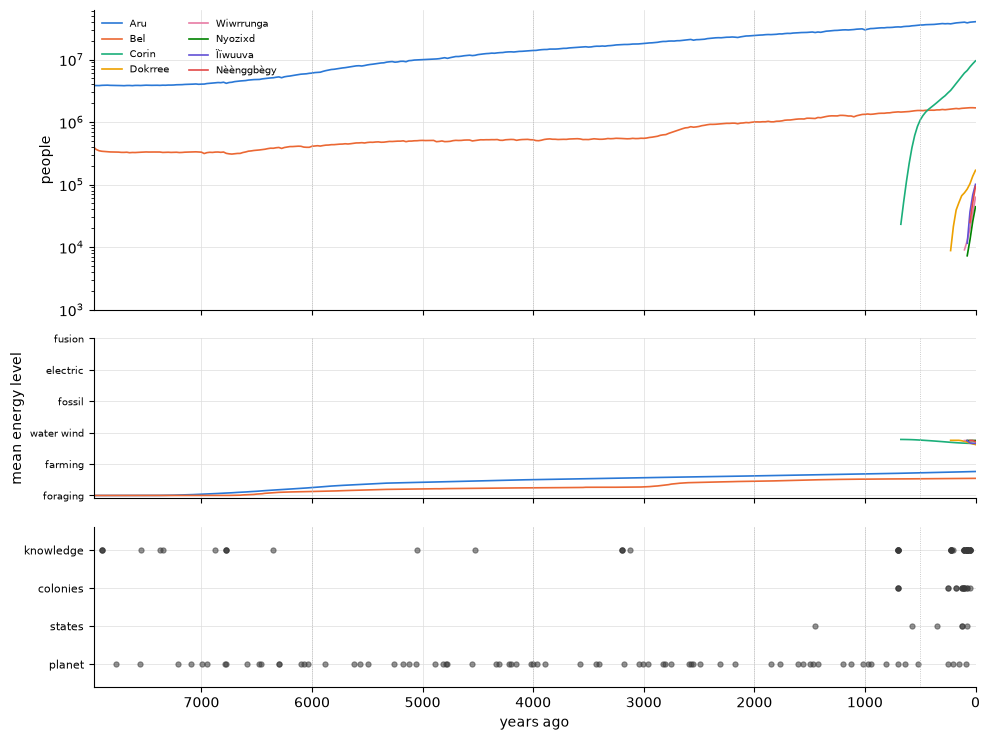

In [6]:
fig = plot_chronicle(world)

In [7]:
s = civ.series
for c in civ.cultures:
    mine = s.culture == c.id
    if mine.any():
        k = np.argmax(s.people[mine])
        print(f"{c.name or c.id:<14} peak {s.people[mine][k]:>14,.0f} people {s.years_ago[mine][k]:>6,.0f} years ago, "
              f"largest state {s.largest_state_km2[mine].max() / 1e6:5.2f} M km²")

Aru            peak     40,240,457 people      0 years ago, largest state  2.19 M km²
Bel            peak      1,694,058 people     25 years ago, largest state  0.00 M km²
Corin          peak      9,515,605 people      0 years ago, largest state  6.36 M km²
Dokrree        peak        169,285 people      0 years ago, largest state  0.08 M km²
Wiwrrunga      peak         62,666 people      0 years ago, largest state  0.01 M km²
Nyozixd        peak         44,227 people      0 years ago, largest state  0.01 M km²
Ïïwuuva        peak        100,928 people      0 years ago, largest state  0.00 M km²
Nèènggbègy     peak         93,545 people      0 years ago, largest state  0.03 M km²


## 5. Maps at the kept epochs

`plot_epochs` draws one culture field at each kept epoch and `animate_epochs` writes them as a GIF. A state or culture keeps its colour from epoch to epoch. `world_at_epoch` returns the world as it stood at one epoch, for any map or report; on the command line, `--epoch` does the same for `map`, `report`, `zoom` and `culture`.

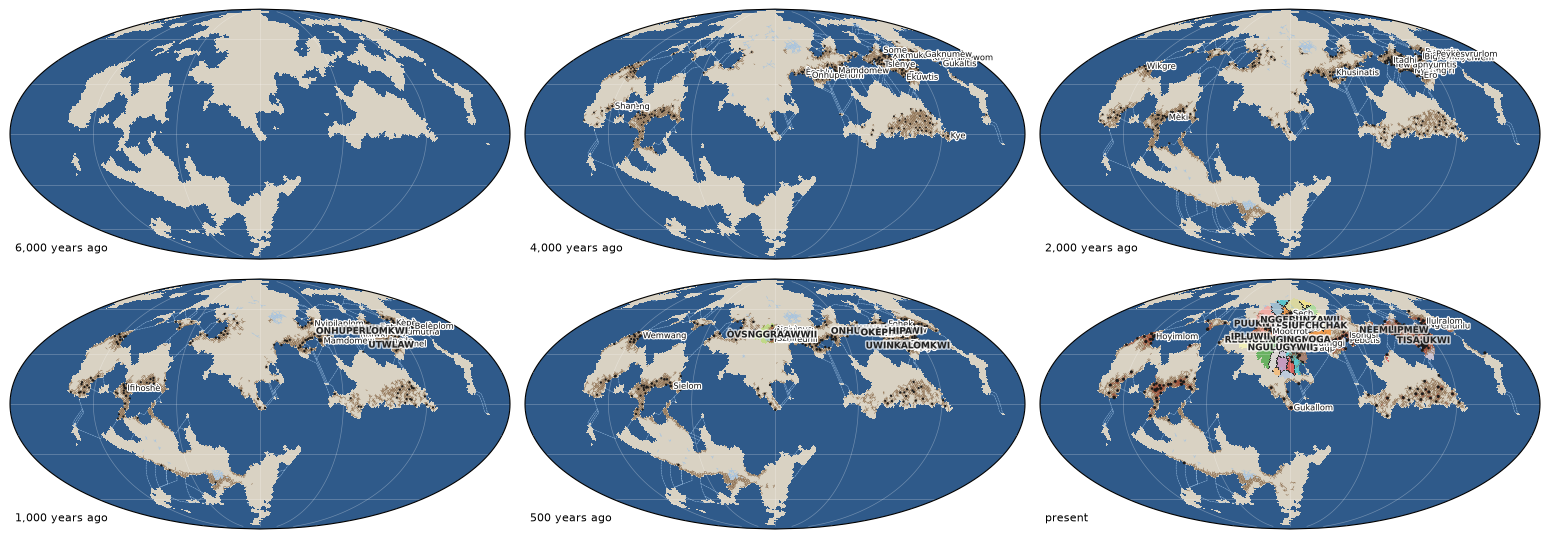

In [8]:
fig = plot_epochs(world, "political")

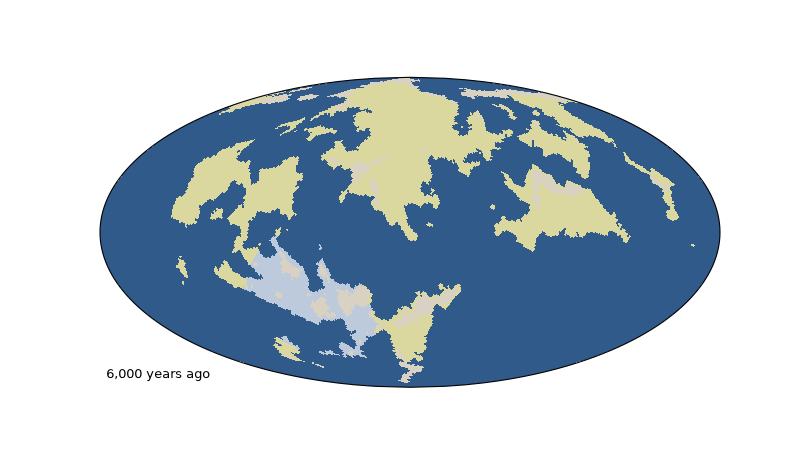

In [9]:
gif = animate_epochs(world, Path(tempfile.mkdtemp()) / "epochs.gif", "cultures", fps=1, width=600)
Image(filename=gif)

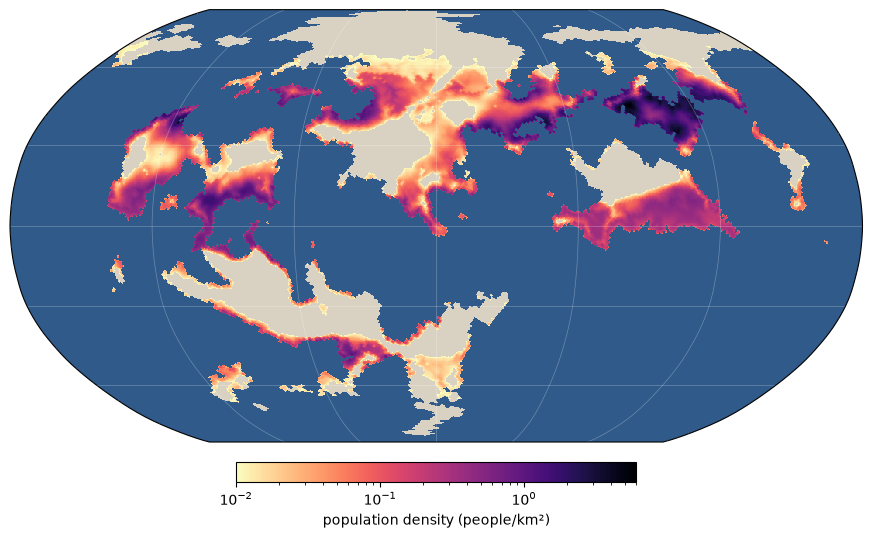

In [10]:
past = world_at_epoch(world, 2000)
ax = plot_map(past, "population", "robinson", title="")

## 6. A region in the past

Zooming works on any epoch: the region's settlements, roads and borders come from the civilisation at that date.

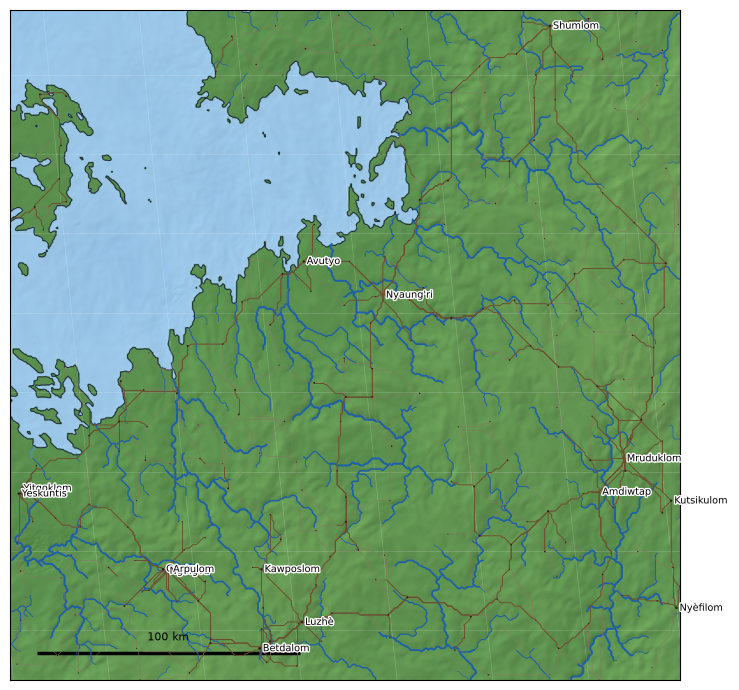

In [11]:
from worldgen.culture.local import zoom_culture
from worldgen.zoom import zoom_region

st = past.culture.settlements
lat, lon = float(st.lat_deg[np.argmax(st.population)]), float(st.lon_deg[np.argmax(st.population)])
region = zoom_region(past, lat, lon, half_width_km=60)
fig = plot_local_map(past, region, culture=zoom_culture(past, region), title="")

## 7. Saving

A saved world keeps the civilisation, its kept epochs (under `culture/epochs/`), the chronicle and the series.

In [12]:
folder = save_world(world, Path(tempfile.mkdtemp()) / "organic")
again = load_world(folder).culture
print([e.epoch_years_ago for e in again.epochs], len(again.chronicle), len(again.series))

[6000.0, 4000.0, 2000.0, 1000.0, 500.0] 168 694
